# Klasifikasi Audio Berisik vs Non-Berisik

## 1. Business Understanding

### 1.1 Latar Belakang

Laboratorium komputer dipakai bersama oleh banyak mahasiswa. Ada saatnya ruangan tenang karena semua orang fokus bekerja, dan ada saatnya ruangan ramai karena diskusi, candaan, atau obrolan yang saling bersahutan. Kondisi ramai yang berlangsung lama mengganggu pengguna lain, padahal asisten atau dosen tidak selalu berada di ruangan untuk menegur.

Secara akustik, kedua kondisi tersebut dapat dibedakan:

1. **Non-berisik.** Suara didominasi derau latar yang stabil, seperti dengung AC, kipas komputer, dan ketikan keyboard sesekali. Energinya rendah dan polanya cenderung datar.
2. **Berisik.** Banyak sumber suara aktif bersamaan, seperti percakapan, tawa, dan gesekan kursi. Energinya tinggi dan berubah-ubah dengan cepat.

Jika komputer dapat mengenali perbedaan ini dari rekaman suara, sistem dapat memberi peringatan otomatis saat ruangan terlalu ramai.

### 1.2 Tujuan

Membangun model *machine learning* yang menerima satu rekaman audio lalu memutuskan apakah rekaman tersebut **berisik** atau **non-berisik**. Tiga metode dibandingkan, yaitu **Random Forest**, **Support Vector Machine (SVM)**, dan **K-Nearest Neighbors (KNN)**, untuk menemukan metode dengan performa terbaik.

## 2. Data Understanding

### 2.1 Dataset

Setiap file berformat `.mp3` dan direkam oleh mahasiswa yang berbeda. Langkah pertama adalah menghitung jumlah file dan durasinya di setiap folder.

In [2]:
from pathlib import Path

import librosa
import pandas as pd

FOLDER_AUDIO = Path('data/audio')
KELAS = ['berisik', 'non-berisik']

daftar = []
for kelas in KELAS:
    for path in sorted((FOLDER_AUDIO / kelas).iterdir()):
        if path.suffix.lower() == '.mp3':
            daftar.append({
                'file': path.name,
                'kelas': kelas,
                'durasi': librosa.get_duration(path=path),
                'path': str(path),
            })

df_file = pd.DataFrame(daftar)

print(f'Total file: {len(df_file)}')
df_file.groupby('kelas')['durasi'].agg(['count', 'min', 'median', 'max']).round(1)

Total file: 200


,count,min,median,max
kelas,,,,
berisik,100,29.8,30.2,48.1
non-berisik,100,29.9,30.2,38.5


Kedua kelas memiliki jumlah file yang hampir sama, dan sebagian besar rekaman berdurasi sekitar 30 detik. Rekaman terpanjang mencapai 48 detik. Perbedaan durasi ini tidak menjadi masalah, karena di tahap agregasi setiap file tetap diringkas menjadi satu baris fitur dengan panjang yang sama.

### 2.2 Visualisasi Sampel

Sebelum masuk ke pemrosesan, satu rekaman dari setiap kelas divisualisasikan untuk melihat perbedaannya secara langsung. Ada dua grafik:

- **Waveform**: amplitudo sinyal terhadap waktu. Makin lebar simpangannya, makin keras suaranya.
- **Spektrogram**: energi pada setiap frekuensi terhadap waktu. Warna terang berarti energinya besar.

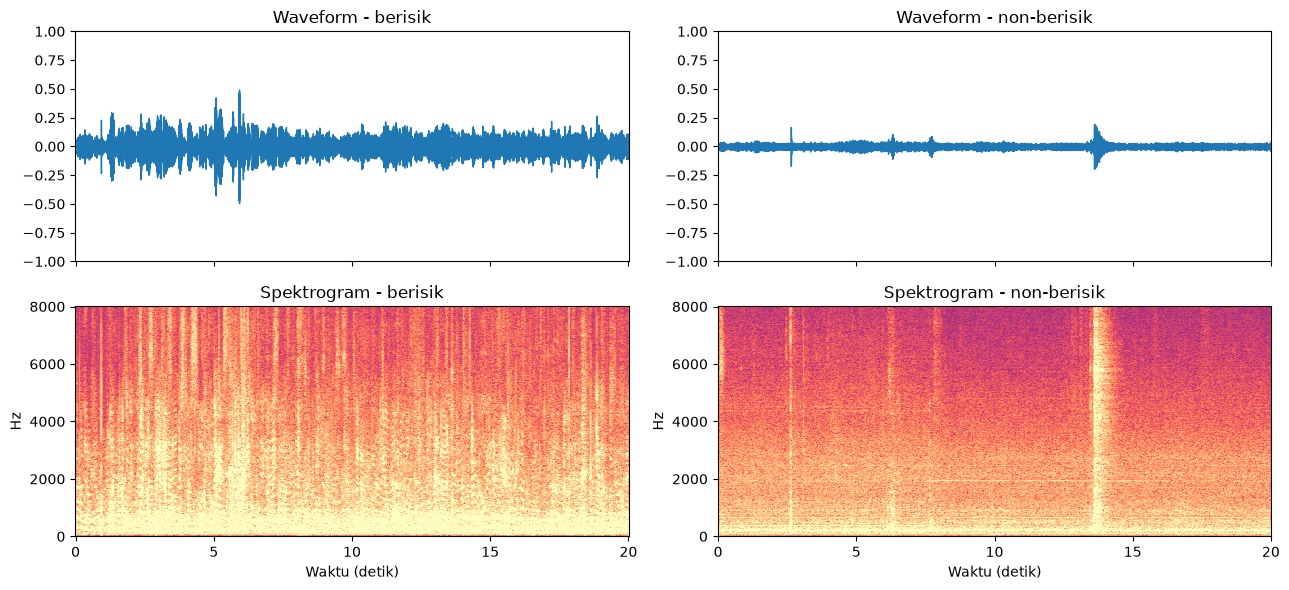

In [3]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

contoh = {
    'berisik': 'data/audio/berisik/24-006 berisik 1.mp3',
    'non-berisik': 'data/audio/non-berisik/24-006 non-berisik 2.mp3',
}

fig, axes = plt.subplots(2, 2, figsize=(13, 6), sharex=True)
for kolom, (kelas, path) in enumerate(contoh.items()):
    sinyal, sr = librosa.load(path, sr=16000, res_type='polyphase', duration=20)

    librosa.display.waveshow(sinyal, sr=sr, ax=axes[0, kolom])
    axes[0, kolom].set(title=f'Waveform - {kelas}', ylim=(-1, 1), xlabel='')

    spektrum = librosa.amplitude_to_db(np.abs(librosa.stft(sinyal)), ref=1.0)
    librosa.display.specshow(spektrum, sr=sr, x_axis='time', y_axis='hz',
                             ax=axes[1, kolom], vmin=-100, vmax=0, cmap='magma')
    axes[1, kolom].set(title=f'Spektrogram - {kelas}', xlabel='Waktu (detik)')

plt.tight_layout()
plt.show()

Rekaman berisik memiliki simpangan amplitudo yang lebar di sepanjang rekaman, dan spektrogramnya terang hampir di semua frekuensi, terutama di bawah 2.000 Hz (rentang suara percakapan). Rekaman non-berisik hampir datar, dengan beberapa lonjakan singkat seperti ketukan atau benda jatuh. Perbedaan kenyaringan, sebaran frekuensi, dan fluktuasi inilah yang akan diukur oleh fitur-fitur di Bab 4.

## 3. Pra-pemrosesan

Rekaman mentah memiliki *sample rate* dan panjang yang berbeda-beda, dan sebagian bisa berisi bagian hening (misalnya jeda sebelum perekaman dimulai). Pra-pemrosesan membuat semua rekaman berada pada kondisi yang sama sebelum fiturnya dihitung. Ada tiga langkah: *resample*, *chunking*, dan buang hening.

### 3.1 Resample ke 16 kHz

*Sample rate* adalah jumlah sampel amplitudo yang diambil setiap detik. Rekaman dari HP umumnya memakai 44.100 atau 48.000 Hz. Semua rekaman diseragamkan menjadi **16.000 Hz** karena:

- Menurut teorema Nyquist, *sample rate* 16 kHz dapat merekam frekuensi hingga 8 kHz, dan rentang itu sudah mencakup hampir seluruh energi suara percakapan.
- Jumlah sampel menjadi sekitar 3 kali lebih sedikit, sehingga proses ekstraksi lebih cepat.
- Fitur dari rekaman yang berbeda *sample rate*-nya tidak dapat dibandingkan secara langsung, jadi semua harus diseragamkan.

`librosa.load` dengan `sr=16000` langsung melakukan *resample* saat file dibaca. Parameter `res_type='polyphase'` memilih metode *resampling* polifase dari SciPy.

In [4]:
import librosa

FILE_CONTOH = 'data/audio/berisik/24-006 berisik 1.mp3'

sinyal_asli, sr_asli = librosa.load(FILE_CONTOH, sr=None)
sinyal, sr = librosa.load(FILE_CONTOH, sr=16000, res_type='polyphase')

print(f'Sebelum: {sr_asli:>6} Hz -> {len(sinyal_asli):>9,} sampel ({len(sinyal_asli) / sr_asli:.1f} detik)')
print(f'Sesudah: {sr:>6} Hz -> {len(sinyal):>9,} sampel ({len(sinyal) / sr:.1f} detik)')

Sebelum:  44100 Hz -> 1,352,510 sampel (30.7 detik)
Sesudah:  16000 Hz ->   490,707 sampel (30.7 detik)


Durasinya tetap sama, tetapi jumlah sampelnya turun drastis. Ini menunjukkan *resample* hanya mengubah kerapatan sampel, bukan isi rekaman.

### 3.2 Chunking 5 Detik

Rekaman kemudian dipotong menjadi *chunk* (potongan) berdurasi **5 detik** tanpa tumpang-tindih. Rekaman 30 detik menghasilkan 6 *chunk*, dan sisa di akhir yang kurang dari 5 detik dibuang.

Chunking punya dua fungsi:

1. Setiap bagian rekaman dapat diperiksa satu per satu. Jika ada bagian yang hampir seluruhnya hening, cukup bagian itu yang dibuang, bukan seluruh rekaman.
2. Panjang 5 detik sama dengan jendela yang nantinya dipakai sistem *real-time*: setiap 5 detik, sistem mendengarkan lalu memutuskan.

In [5]:
def potong_chunk(sinyal, sr=16000, durasi=5):
    """Bagi sinyal menjadi potongan berdurasi tetap; sisa di akhir yang kurang dari durasi dibuang."""
    panjang = int(durasi * sr)
    return [sinyal[i:i + panjang] for i in range(0, len(sinyal) - panjang + 1, panjang)]


chunks = potong_chunk(sinyal, sr)

print(f'Durasi rekaman : {len(sinyal) / sr:.1f} detik')
print(f'Jumlah chunk   : {len(chunks)}')
print(f'Panjang chunk  : {len(chunks[0]):,} sampel = {len(chunks[0]) / sr:.0f} detik')

Durasi rekaman : 30.7 detik
Jumlah chunk   : 6
Panjang chunk  : 80,000 sampel = 5 detik


### 3.3 Buang Bagian Hening

Bagian hening tidak membawa informasi tentang kondisi ruangan. Untuk mendeteksinya, setiap *chunk* dibagi lagi menjadi **frame** pendek (2.048 sampel atau sekitar 0,13 detik, bergeser setiap 512 sampel), lalu energi (RMS) setiap frame dihitung dalam satuan **dBFS**:

$$\text{dBFS} = 20 \cdot \log_{10}(\text{RMS})$$

Nilai 0 dBFS adalah amplitudo maksimum digital, dan makin negatif berarti makin pelan. Aturannya:

- Frame dengan energi **di bawah −80 dBFS** dianggap hening, dan tidak ikut dihitung saat agregasi.
- *Chunk* yang **lebih dari separuh frame-nya hening** dibuang seluruhnya.

**Mengapa ambangnya −80 dBFS?** Pada kasus ini, kenyaringan adalah ciri utama yang membedakan kedua kelas. Jika ambang dibuat terlalu tinggi, suasana tenang dari rekaman non-berisik ikut dianggap hening dan terbuang. Akibatnya, yang tersisa hanya bunyi-bunyi yang lebih keras, sehingga rekaman non-berisik tampak lebih ramai dari aslinya.

Saat data diperiksa, derau latar ruangan tenang pada beberapa HP bisa serendah −60 sampai −75 dBFS, dan suara itu masih termasuk informasi kondisi ruangan. Sebaliknya, frame yang benar-benar hening, misalnya bernilai nol karena fitur peredam derau (*noise gate*) HP atau jeda sebelum rekaman dimulai, berada jauh di bawah −80 dBFS. Ambang −80 dBFS memisahkan kedua kondisi tersebut.

In [6]:
import librosa
import numpy as np

AMBANG_DB = -80
MIN_FRAME_AKTIF = 0.5


def frame_aktif(chunk):
    """Kembalikan mask frame yang energinya di atas ambang hening."""
    rms = librosa.feature.rms(y=chunk, frame_length=2048, hop_length=512)[0]
    return 20 * np.log10(rms + 1e-10) > AMBANG_DB


FILE_HENING = 'data/audio/non-berisik/24-007 non-berisik 1.mp3'
sinyal_tenang, sr = librosa.load(FILE_HENING, sr=16000, res_type='polyphase')

for i, chunk in enumerate(potong_chunk(sinyal_tenang, sr), start=1):
    aktif = frame_aktif(chunk)
    status = 'dipakai' if aktif.mean() >= MIN_FRAME_AKTIF else 'DIBUANG'
    print(f'Chunk {i}: {aktif.mean() * 100:5.1f}% frame aktif -> {status}')

Chunk 1:  45.9% frame aktif -> DIBUANG
Chunk 2:  66.9% frame aktif -> dipakai
Chunk 3:  58.6% frame aktif -> dipakai
Chunk 4:  70.1% frame aktif -> dipakai
Chunk 5:  51.0% frame aktif -> dipakai
Chunk 6:  42.0% frame aktif -> DIBUANG


Contoh di atas diambil dari salah satu rekaman non-berisik yang sangat tenang. Grafik berikut memperlihatkan energi frame-nya beserta garis ambang −80 dBFS.

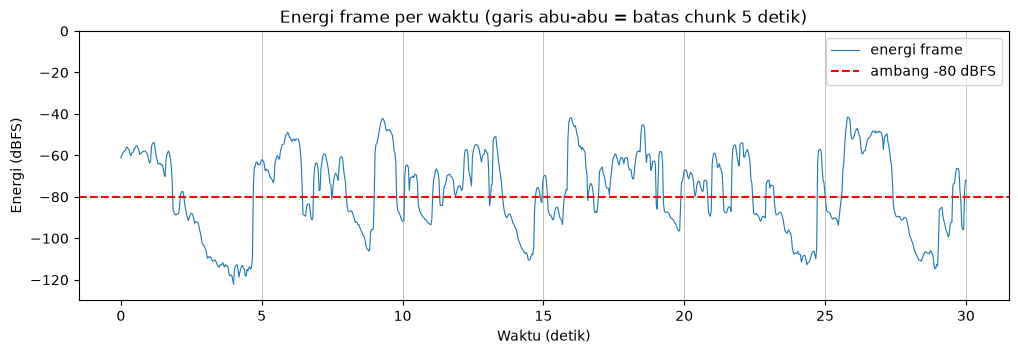

In [7]:
import librosa
import matplotlib.pyplot as plt
import numpy as np

rms = librosa.feature.rms(y=sinyal_tenang, frame_length=2048, hop_length=512)[0]
db = 20 * np.log10(rms + 1e-10)
waktu = librosa.frames_to_time(np.arange(len(db)), sr=16000, hop_length=512)

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(waktu, db, lw=0.8, label='energi frame')
ax.axhline(AMBANG_DB, color='red', ls='--', label=f'ambang {AMBANG_DB} dBFS')
for batas in range(5, int(waktu[-1]) + 1, 5):
    ax.axvline(batas, color='gray', lw=0.6, alpha=0.6)
ax.set(xlabel='Waktu (detik)', ylabel='Energi (dBFS)', ylim=(-130, 0),
       title='Energi frame per waktu (garis abu-abu = batas chunk 5 detik)')
ax.legend(loc='upper right')
plt.show()

Frame yang berada di bawah garis merah tidak akan ikut dihitung. Berikut ketiga langkah pra-pemrosesan yang digabung menjadi satu fungsi. Fungsi ini mengembalikan daftar *chunk* yang layak dipakai beserta mask frame aktifnya.

In [8]:
import librosa


def praproses(path):
    """Resample ke 16 kHz -> potong chunk 5 detik -> buang chunk yang dominan hening."""
    sinyal, sr = librosa.load(path, sr=16000, res_type='polyphase')

    hasil = []
    for chunk in potong_chunk(sinyal, sr):
        aktif = frame_aktif(chunk)
        if aktif.mean() >= MIN_FRAME_AKTIF:
            hasil.append((chunk, aktif))
    return hasil, sr


hasil_contoh, _ = praproses(FILE_HENING)
print(f'{FILE_HENING}: {len(hasil_contoh)} chunk layak dipakai')

data/audio/non-berisik/24-007 non-berisik 1.mp3: 4 chunk layak dipakai


## 4. Ekstraksi Fitur

Komputer tidak dapat mengklasifikasikan gelombang suara secara langsung. Sinyal perlu diubah menjadi angka-angka yang menggambarkan sifatnya, yang disebut **fitur**. Semua fitur di bawah dihitung **per frame** (2.048 sampel, bergeser 512 sampel), sehingga setiap *chunk* 5 detik menghasilkan sekitar 157 nilai untuk setiap fitur.

Setiap fitur dibahas dengan pola yang sama: apa yang diukur, rumusnya, contoh perhitungan kecil, lalu pengecekan dengan kode.

### 4.1 RMS (Root Mean Square)

**Apa yang diukur.** RMS adalah energi efektif sinyal dalam satu frame. Nilainya sejalan dengan kenyaringan yang didengar telinga: ruangan ramai menghasilkan RMS tinggi, ruangan tenang menghasilkan RMS mendekati nol.

**Rumus.** Untuk frame $x$ yang berisi $N$ sampel:

$$\text{RMS} = \sqrt{\frac{1}{N}\sum_{n=0}^{N-1} x[n]^2}$$

**Contoh perhitungan.** Misalkan satu frame kecil berisi 4 sampel: $x = [0.3,\ -0.5,\ 0.2,\ -0.4]$

1. Kuadratkan setiap sampel: $[0.09,\ 0.25,\ 0.04,\ 0.16]$
2. Jumlahkan: $0.09 + 0.25 + 0.04 + 0.16 = 0.54$
3. Bagi dengan $N = 4$: $0.54 / 4 = 0.135$
4. Akarkan: $\sqrt{0.135} \approx 0.3674$

Pengecekan hasil hitungan manual dengan NumPy:

In [9]:
import numpy as np

x = np.array([0.3, -0.5, 0.2, -0.4])
rms_manual = np.sqrt(np.mean(x ** 2))

print(f'RMS = {rms_manual:.4f}')

RMS = 0.3674


Hasilnya sama dengan perhitungan manual. Di librosa, fitur ini dihitung dengan `librosa.feature.rms(y=chunk, frame_length=2048, hop_length=512)`.

### 4.2 Spectral Centroid (Pusat Spektrum)

**Apa yang diukur.** *Spectral centroid* adalah "titik berat" frekuensi dalam satu frame, yaitu frekuensi rata-rata yang ditimbang dengan besar energinya. Suara yang tajam atau melengking (tawa, teriakan, gesekan kursi) menarik centroid ke frekuensi tinggi. Dengung mesin dan AC yang berfrekuensi rendah membuat centroid lebih rendah.

**Rumus.** Frame diubah dulu ke domain frekuensi dengan STFT (*Short-Time Fourier Transform*). Jika $f(k)$ adalah frekuensi pada *bin* ke-$k$ dan $|S(k)|$ adalah magnitudonya:

$$\text{Centroid} = \frac{\sum_{k} f(k)\cdot|S(k)|}{\sum_{k}|S(k)|}$$

**Contoh perhitungan.** Misalkan satu frame hanya memiliki tiga *bin* frekuensi:

| Bin | Frekuensi $f(k)$ | Magnitudo $\|S(k)\|$ |
|---|---|---|
| 1 | 250 Hz | 4 |
| 2 | 1.000 Hz | 3 |
| 3 | 3.000 Hz | 1 |

1. Pembilang: $(250 \times 4) + (1000 \times 3) + (3000 \times 1) = 1000 + 3000 + 3000 = 7000$
2. Penyebut: $4 + 3 + 1 = 8$
3. Centroid: $7000 / 8 = 875$ Hz

Meskipun ada komponen di 3.000 Hz, energinya kecil, sehingga titik berat spektrum tetap berada di bawah 1.000 Hz.

In [10]:
import numpy as np

frekuensi = np.array([250, 1000, 3000])
magnitudo = np.array([4, 3, 1])
centroid_manual = np.sum(frekuensi * magnitudo) / np.sum(magnitudo)

print(f'Spectral centroid = {centroid_manual:.0f} Hz')

Spectral centroid = 875 Hz


Di librosa: `librosa.feature.spectral_centroid(y=chunk, sr=sr, n_fft=2048, hop_length=512)`.

### 4.3 ZCR (Zero Crossing Rate / Laju Lintas Nol)

**Apa yang diukur.** ZCR adalah seberapa sering sinyal berpindah tanda, dari positif ke negatif atau sebaliknya, dalam satu frame. Suara acak dan berdesis (obrolan yang bertumpuk, gesekan) sering melintasi garis nol sehingga ZCR-nya tinggi. Suara yang halus dan periodik melintasi nol lebih jarang.

**Rumus.** Untuk frame dengan $N$ sampel, di mana $\mathbb{1}[\cdot]$ bernilai 1 jika kondisinya benar dan 0 jika salah:

$$\text{ZCR} = \frac{1}{N}\sum_{n=1}^{N-1}\mathbb{1}\big[\operatorname{sign}(x[n]) \neq \operatorname{sign}(x[n-1])\big]$$

**Contoh perhitungan.** Misalkan frame berisi 6 sampel: $x = [0.4,\ 0.1,\ -0.2,\ -0.3,\ 0.5,\ -0.1]$

| Pasangan | Tanda | Melintasi nol? |
|---|---|---|
| 0.4 → 0.1 | + → + | tidak |
| 0.1 → −0.2 | + → − | **ya** |
| −0.2 → −0.3 | − → − | tidak |
| −0.3 → 0.5 | − → + | **ya** |
| 0.5 → −0.1 | + → − | **ya** |

Terjadi 3 kali lintas nol dari 6 sampel, sehingga $\text{ZCR} = 3/6 = 0.5$.

In [11]:
import numpy as np

x = np.array([0.4, 0.1, -0.2, -0.3, 0.5, -0.1])
lintas = np.sum(np.signbit(x[1:]) != np.signbit(x[:-1]))
zcr_manual = lintas / len(x)

print(f'Jumlah lintas nol = {lintas}')
print(f'ZCR               = {zcr_manual:.2f}')

Jumlah lintas nol = 3
ZCR               = 0.50


Di librosa: `librosa.feature.zero_crossing_rate(chunk, frame_length=2048, hop_length=512)`. Librosa membagi jumlah lintas nol dengan panjang frame, sama seperti contoh di atas.

### 4.4 MFCC (Mel-Frequency Cepstral Coefficients)

**Apa yang diukur.** MFCC merangkum **bentuk spektrum** suara menggunakan skala yang meniru pendengaran manusia. Telinga manusia peka terhadap perbedaan frekuensi rendah, tetapi kurang peka di frekuensi tinggi. MFCC membantu membedakan jenis suara (orang bercakap versus dengung mesin) meskipun kenyaringannya mirip. Modul menggunakan **13 koefisien**.

**Tahapan pembentukan MFCC:**

1. **STFT.** Ubah frame ke spektrum daya $P(k) = |S(k)|^2$.
2. **Skala Mel.** Petakan frekuensi Hz ke skala Mel agar sesuai pendengaran manusia:
   $$m = 2595 \cdot \log_{10}\left(1 + \frac{f}{700}\right)$$
3. **Mel filterbank.** Jumlahkan energi spektrum pada sederet filter segitiga yang tersusun rapat di frekuensi rendah dan renggang di frekuensi tinggi.
4. **Logaritma.** Ambil log dari energi setiap filter, karena telinga mendengar kenyaringan secara logaritmik.
5. **DCT (Discrete Cosine Transform).** Ringkas log-energi filter menjadi koefisien yang tidak saling berkorelasi, lalu ambil 13 koefisien pertama.

**Contoh perhitungan skala Mel (langkah 2).** Perhatikan bagaimana jarak 1.000 Hz di frekuensi rendah dan tinggi menjadi berbeda setelah diubah ke Mel:

| Frekuensi | Perhitungan | Mel |
|---|---|---|
| 500 Hz | $2595 \cdot \log_{10}(1 + 500/700)$ | ≈ 607 |
| 1.500 Hz | $2595 \cdot \log_{10}(1 + 1500/700)$ | ≈ 1.291 |
| 6.000 Hz | $2595 \cdot \log_{10}(1 + 6000/700)$ | ≈ 2.545 |
| 7.000 Hz | $2595 \cdot \log_{10}(1 + 7000/700)$ | ≈ 2.702 |

Jarak 500 → 1.500 Hz menjadi 684 Mel, sedangkan jarak 6.000 → 7.000 Hz hanya 157 Mel. Artinya, MFCC memberi "resolusi" lebih besar pada frekuensi rendah, tempat sebagian besar informasi suara manusia berada.

In [12]:
import numpy as np

for f in [500, 1500, 6000, 7000]:
    mel = 2595 * np.log10(1 + f / 700)
    print(f'{f:>5} Hz -> {mel:7.1f} Mel')

  500 Hz ->   607.4 Mel
 1500 Hz ->  1290.6 Mel
 6000 Hz ->  2545.6 Mel
 7000 Hz ->  2702.4 Mel


Koefisien pertama (MFCC 1) sebanding dengan log-energi total frame, sehingga nilainya ikut mencerminkan kenyaringan. Koefisien 2–13 menggambarkan bentuk spektrum secara makin detail. Di librosa: `librosa.feature.mfcc(y=chunk, sr=sr, n_mfcc=13, n_fft=2048, hop_length=512)`, yang menghasilkan matriks berukuran 13 × jumlah frame.

### 4.5 Fungsi Ekstraksi Fitur per Frame

Keempat fitur digabung dalam satu fungsi yang menerima satu *chunk* dan mengembalikan **16 deret nilai per frame**: RMS, centroid, ZCR, dan MFCC 1–13. Hanya frame aktif (hasil langkah buang hening) yang disimpan.

In [40]:
import librosa
import numpy as np
import pandas as pd
from pathlib import Path

NAMA_DERET = ['rms', 'centroid', 'zcr'] + [f'mfcc{i}' for i in range(1, 14)]

def fitur_per_frame(chunk, aktif, sr=16000):
    rms = librosa.feature.rms(y=chunk, frame_length=2048, hop_length=512)
    centroid = librosa.feature.spectral_centroid(y=chunk, sr=sr, n_fft=2048, hop_length=512)
    zcr = librosa.feature.zero_crossing_rate(chunk, frame_length=2048, hop_length=512)
    mfcc = librosa.feature.mfcc(y=chunk, sr=sr, n_mfcc=13, n_fft=2048, hop_length=512)

    semua = np.vstack([rms, centroid, zcr, mfcc])
    return semua[:, aktif]

# Pastikan folder data/processed sudah ada, jika belum buat terlebih dahulu
Path('data/processed').mkdir(parents=True, exist_ok=True)

FILE_CONTOH = 'data/audio/berisik/24-027_berisik1.mp3'
kelas_audio = 'berisik' 

# Asumsi fungsi praproses sudah berjalan normal
chunk_contoh, aktif_contoh = praproses(FILE_CONTOH)[0][0]
deret = fitur_per_frame(chunk_contoh, aktif_contoh)

# 1. Buat DataFrame dari hasil transpose
df_fitur = pd.DataFrame(deret.T, columns=NAMA_DERET)

# 2. Sisipkan kolom 'file' dan 'kelas'
df_fitur.insert(0, 'file', Path(FILE_CONTOH).name)
df_fitur.insert(17, 'kelas', kelas_audio)

# 3. Simpan ke SATU file CSV saja
print(f'Ukuran output satu chunk: {deret.shape[0]} fitur x {deret.shape[1]} frame')
nama_file_keluaran = 'data/processed/fitur_audio_lengkap.csv'
df_fitur.to_csv(nama_file_keluaran, index=False)

print(f'Data berhasil disimpan di: {nama_file_keluaran}')
print('\n5 baris pertama:')
print(df_fitur.head())

Ukuran output satu chunk: 16 fitur x 157 frame
Data berhasil disimpan di: data/processed/fitur_audio_lengkap.csv

5 baris pertama:
                  file       rms     centroid       zcr       mfcc1  \
0  24-027_berisik1.mp3  0.000151  1552.901893  0.104004 -753.393372   
1  24-027_berisik1.mp3  0.001605  1365.535681  0.123047 -642.008545   
2  24-027_berisik1.mp3  0.003985  1214.474206  0.139648 -515.067017   
3  24-027_berisik1.mp3  0.008344  1079.347707  0.096680 -442.374664   
4  24-027_berisik1.mp3  0.011067   956.700491  0.063477 -390.756409   

        mfcc2      mfcc3      mfcc4      mfcc5      mfcc6      mfcc7  \
0    0.000000   0.000000   0.000000   0.000000   0.000000   0.000000   
1   88.208328  15.022564   4.825811  -5.897980 -10.319754  -2.848708   
2  114.457199   0.188424  21.430754 -14.134743  -4.100237 -13.328598   
3  127.695305  -6.420610  20.521721 -17.228367  -2.059705 -21.902445   
4  134.875885  -8.356873  16.872564 -21.938431  -6.752129 -24.682011   

       mf

Satu *chunk* 5 detik menghasilkan matriks 16 × 157. Setiap baris adalah satu fitur, dan setiap kolom adalah satu frame. Grafik berikut memperlihatkan bagaimana tiga fitur utama berubah sepanjang waktu pada sampel berisik dan non-berisik.

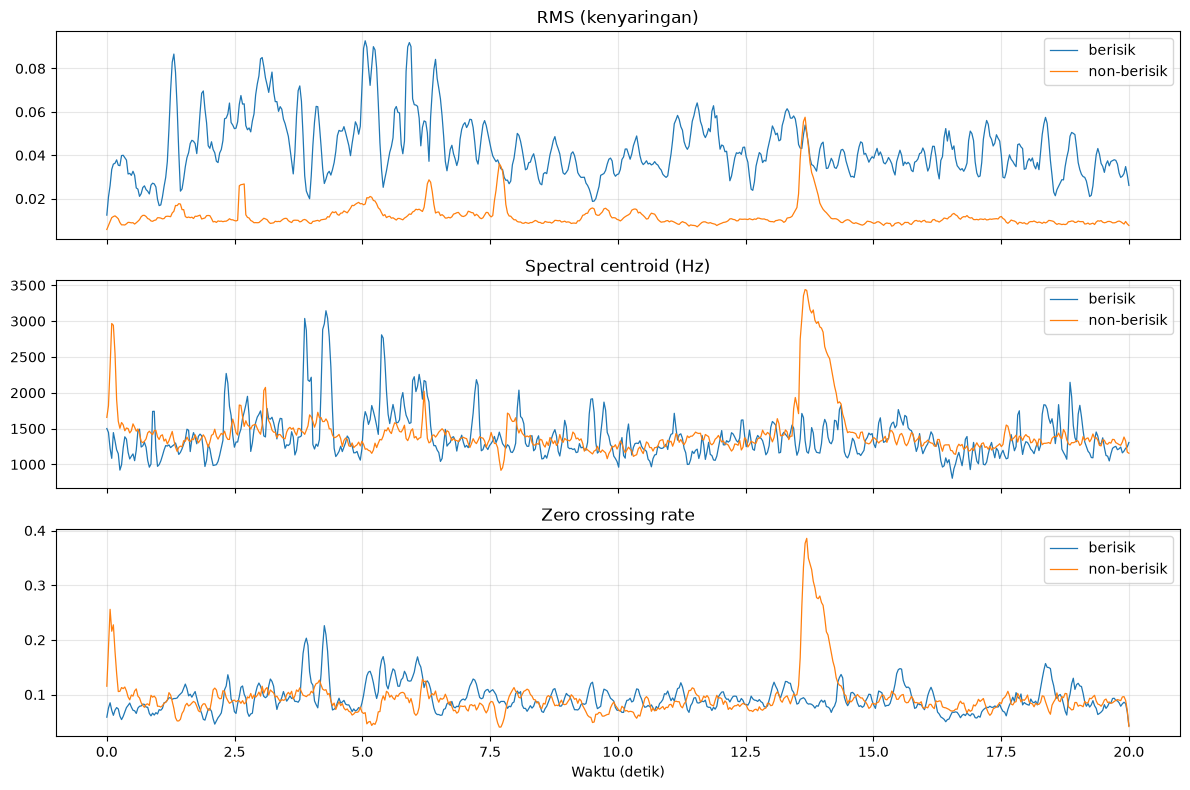

In [15]:
import librosa
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
judul = ['RMS (kenyaringan)', 'Spectral centroid (Hz)', 'Zero crossing rate']

for kelas, path in contoh.items():
    sinyal, sr = librosa.load(path, sr=16000, res_type='polyphase', duration=20)
    nilai = [
        librosa.feature.rms(y=sinyal, frame_length=2048, hop_length=512)[0],
        librosa.feature.spectral_centroid(y=sinyal, sr=sr, n_fft=2048, hop_length=512)[0],
        librosa.feature.zero_crossing_rate(sinyal, frame_length=2048, hop_length=512)[0],
    ]
    waktu = librosa.frames_to_time(np.arange(len(nilai[0])), sr=sr, hop_length=512)
    for ax, deret_fitur in zip(axes, nilai):
        ax.plot(waktu, deret_fitur, lw=0.9, label=kelas)

for ax, teks in zip(axes, judul):
    ax.set_title(teks)
    ax.legend(loc='upper right')
    ax.grid(alpha=0.3)
axes[-1].set_xlabel('Waktu (detik)')
plt.tight_layout()
plt.show()

RMS memperlihatkan perbedaan paling jelas: garis berisik berada jauh di atas garis non-berisik dan terus naik-turun. Centroid dan ZCR keduanya berfluktuasi dan saling tumpang-tindih, tetapi rekaman berisik cenderung lebih bergejolak. Perbedaan **tingkat** (rata-rata) dan **gejolak** (variasi) inilah yang akan diringkas di tahap agregasi.

## 5. Agregasi Fitur

### 5.1 Dari Deret Waktu Menjadi Satu Baris per File

Model klasifikasi membutuhkan input berukuran tetap, sedangkan jumlah frame setiap file berbeda-beda bergantung pada durasinya. Karena itu, frame aktif dari semua *chunk* dalam satu file digabung, lalu setiap fitur diringkas dengan dua statistik:

- **Mean (rata-rata)** menggambarkan tingkat umum fitur, misalnya seberapa keras rekaman secara keseluruhan.
- **Standar deviasi (std)** menggambarkan seberapa besar fitur berubah-ubah, misalnya apakah suaranya stabil atau naik-turun.

$$\mu = \frac{1}{T}\sum_{t=1}^{T} v_t \qquad\qquad \sigma = \sqrt{\frac{1}{T}\sum_{t=1}^{T}(v_t - \mu)^2}$$

dengan $v_t$ adalah nilai fitur pada frame ke-$t$, dan $T$ adalah jumlah frame aktif dalam satu file.

**Contoh perhitungan.** Misalkan nilai RMS dari 4 frame adalah $[0.02,\ 0.06,\ 0.04,\ 0.08]$.

- $\mu = (0.02 + 0.06 + 0.04 + 0.08)/4 = 0.05$
- $\sigma = \sqrt{\big((−0.03)^2 + 0.01^2 + (−0.01)^2 + 0.03^2\big)/4} = \sqrt{0.0005} \approx 0.0224$

In [16]:
import numpy as np

v = np.array([0.02, 0.06, 0.04, 0.08])
print(f'mean = {v.mean():.4f}')
print(f'std  = {v.std():.4f}')

mean = 0.0500
std  = 0.0224


Karena ada 16 deret fitur dan masing-masing diringkas dengan 2 statistik, setiap file menghasilkan **32 fitur**:

| Kelompok | Fitur | Jumlah |
|---|---|---|
| RMS | `rms_mean`, `rms_std` | 2 |
| Spectral centroid | `centroid_mean`, `centroid_std` | 2 |
| ZCR | `zcr_mean`, `zcr_std` | 2 |
| MFCC | `mfcc1_mean` … `mfcc13_mean`, `mfcc1_std` … `mfcc13_std` | 26 |
| **Total** | | **32** |

### 5.2 Pipeline Lengkap per File

Fungsi `ekstrak_file` menyatukan seluruh langkah sebelumnya: pra-pemrosesan → ekstraksi per frame → agregasi.

In [17]:
import numpy as np


def ekstrak_file(path):
    """Satu file audio -> dict 32 fitur (mean & std dari frame aktif di semua chunk)."""
    hasil, sr = praproses(path)
    if not hasil:
        return None

    deret = np.hstack([fitur_per_frame(chunk, aktif, sr) for chunk, aktif in hasil])

    fitur = {}
    for nama, nilai in zip(NAMA_DERET, deret):
        fitur[f'{nama}_mean'] = nilai.mean()
    for nama, nilai in zip(NAMA_DERET, deret):
        fitur[f'{nama}_std'] = nilai.std()
    fitur['jumlah_chunk'] = len(hasil)
    return fitur


fitur_contoh = ekstrak_file(FILE_CONTOH)
print(f'Jumlah fitur: {len(fitur_contoh) - 1} (+ kolom jumlah_chunk)')
{k: round(float(v), 4) for k, v in list(fitur_contoh.items())[:6]}

Jumlah fitur: 32 (+ kolom jumlah_chunk)


{'rms_mean': 0.0414,
 'centroid_mean': 1391.6692,
 'zcr_mean': 0.0932,
 'mfcc1_mean': -196.1659,
 'mfcc2_mean': 118.8985,
 'mfcc3_mean': -20.7656}

### 5.3 Ekstraksi Seluruh Dataset

Fungsi dijalankan untuk semua file. Hasilnya disimpan ke `data/processed/fitur_audio.csv` supaya tahap modeling tidak perlu mengulang ekstraksi.

In [18]:
import pandas as pd

baris = []
for _, row in df_file.iterrows():
    fitur = ekstrak_file(row['path'])
    if fitur is None:
        print(f'Dilewati (seluruhnya hening): {row["file"]}')
        continue
    baris.append({'file': row['file'], **fitur, 'label': row['kelas']})

dataset = pd.DataFrame(baris)
dataset.to_csv('data/processed/fitur_audio.csv', index=False)

print(f'\nUkuran dataset: {dataset.shape[0]} baris x {dataset.shape[1]} kolom')
print(dataset['label'].value_counts().to_string())
dataset.head()


Ukuran dataset: 200 baris x 35 kolom
label
berisik        100
non-berisik    100


,file,rms_mean,centroid_mean,zcr_mean,mfcc1_mean,mfcc2_mean,mfcc3_mean,mfcc4_mean,mfcc5_mean,mfcc6_mean,...,mfcc6_std,mfcc7_std,mfcc8_std,mfcc9_std,mfcc10_std,mfcc11_std,mfcc12_std,mfcc13_std,jumlah_chunk,label
0,24-003 berisik (1).mp3,0.042068,1704.054795,0.103362,-219.479456,93.726439,6.988335,5.561003,-6.602791,-19.486007,...,13.330787,13.812380,12.701123,12.092652,10.983585,10.270694,10.474690,8.421232,6,berisik
1,24-003 berisik (2).mp3,0.078241,2116.772900,0.203700,-214.890457,71.376941,-14.685534,29.828256,-53.714796,9.052585,...,19.902041,19.298232,16.797679,17.914293,17.767195,17.146762,15.302479,16.894856,6,berisik
2,24-003 berisik (3).mp3,0.052831,2887.361382,0.331237,-258.689115,40.447754,-7.873307,36.865055,-48.409643,34.385947,...,23.254453,16.340367,20.629039,14.495904,13.225801,14.279496,12.585303,14.759299,6,berisik
3,24-006 berisik 1.mp3,0.041443,1391.669246,0.093184,-196.165867,118.898524,-20.765600,19.345215,-20.194057,-11.408937,...,9.888567,8.150056,8.618076,9.053684,7.295773,7.155462,6.548198,7.201231,6,berisik
4,24-006 berisik 2.mp3,0.031411,1343.086302,0.086109,-240.350266,123.218088,-18.344570,14.401619,-16.579570,-6.911500,...,11.126530,9.748846,9.219045,9.400933,8.874233,7.861458,7.273640,7.639933,6,berisik


Seluruh 208 file berhasil diekstraksi, dan tidak ada file yang seluruh isinya hening. Dataset akhir berbentuk tabel **208 baris × 35 kolom**: 1 kolom nama file, 32 kolom fitur, 1 kolom jumlah *chunk* yang dipakai, dan 1 kolom label. Kolom `jumlah_chunk` hanya dipakai sebagai informasi dan tidak ikut menjadi input model.

### 5.4 Sebaran Fitur per Kelas

Boxplot berikut memperlihatkan seberapa terpisah nilai beberapa fitur di antara kedua kelas. Makin sedikit kotak kedua kelas bertumpuk, makin berguna fitur tersebut untuk klasifikasi.

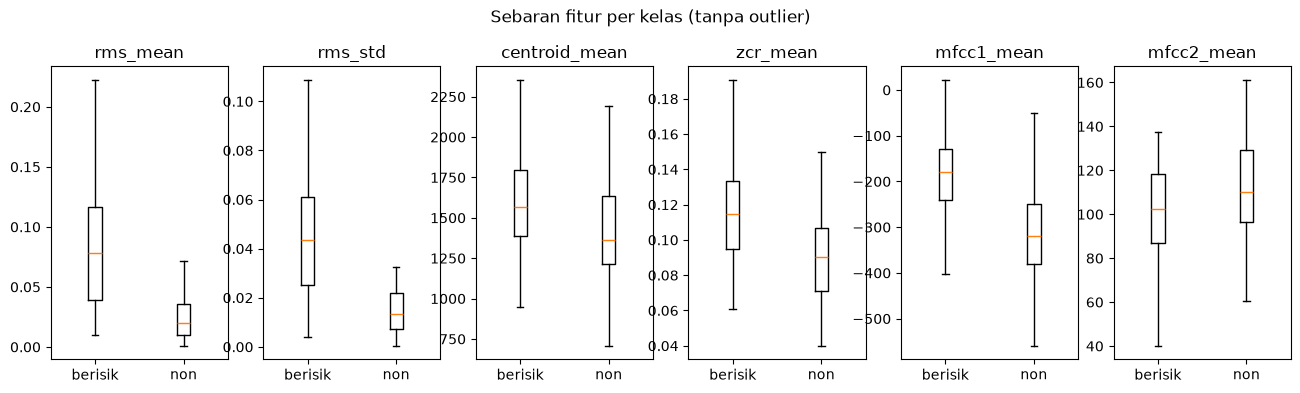

In [19]:
import matplotlib.pyplot as plt

tampil = ['rms_mean', 'rms_std', 'centroid_mean', 'zcr_mean', 'mfcc1_mean', 'mfcc2_mean']

fig, axes = plt.subplots(1, len(tampil), figsize=(16, 3.8))
for ax, kolom in zip(axes, tampil):
    ax.boxplot([dataset.loc[dataset['label'] == k, kolom] for k in ['berisik', 'non-berisik']],
               showfliers=False)
    ax.set_xticks([1, 2], ['berisik', 'non'])
    ax.set_title(kolom)
fig.suptitle('Sebaran fitur per kelas (tanpa outlier)', y=1.03)
plt.show()

Hasil yang terlihat dari boxplot:

- **`rms_mean`, `rms_std`, dan `mfcc1_mean` paling jelas terpisah.** Kotak kedua kelas hampir tidak bertumpuk: rekaman berisik lebih keras (`rms_mean` tinggi) dan kenyaringannya lebih berubah-ubah (`rms_std` tinggi). Ini sesuai dengan pengamatan visual di Bab 2 dan 4.
- **`centroid_mean` dan `zcr_mean` sedikit lebih tinggi pada kelas berisik**, tetapi sebarannya banyak bertumpuk. Kedua fitur ini tidak cukup jika dipakai sendiri, tetapi dapat membantu saat kenyaringan dua rekaman mirip.
- **`mfcc2_mean` sedikit lebih rendah pada kelas berisik.** Ini menunjukkan bentuk spektrumnya ikut berbeda, bukan hanya kerasnya.

## 6. Split Data 80:20

Dataset dibagi menjadi **80% data latih** dan **20% data uji** menggunakan `train_test_split`:

- `stratify=y` menjaga proporsi kelas berisik dan non-berisik tetap sama di data latih dan data uji.
- `random_state=42` membuat pembagian selalu sama setiap kali notebook dijalankan, sehingga hasilnya dapat direproduksi.

Karena setiap file sudah menjadi tepat satu baris, satu rekaman tidak mungkin muncul di data latih dan data uji sekaligus. Ini sesuai pesan modul: data dibagi **per file asli**, bukan per potongan.

In [20]:
import pandas as pd
from sklearn.model_selection import train_test_split

dataset = pd.read_csv('data/processed/fitur_audio.csv')
FITUR = [k for k in dataset.columns if k not in ('file', 'jumlah_chunk', 'label')]

X = dataset[FITUR]
y = dataset['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f'Jumlah fitur : {len(FITUR)}')
print(f'Data latih   : {len(X_train)} file')
print(f'Data uji     : {len(X_test)} file')
pd.DataFrame({'latih': y_train.value_counts(), 'uji': y_test.value_counts()})

Jumlah fitur : 32
Data latih   : 160 file
Data uji     : 40 file


,latih,uji
label,,
berisik,80,20
non-berisik,80,20


## 7. Modeling

Tiga metode dilatih dengan cara yang sama agar perbandingannya adil:

1. **Tuning hyperparameter** dengan `GridSearchCV` dan *Stratified 5-Fold Cross Validation* **hanya pada data latih**. Data latih dibagi menjadi 5 bagian, model dilatih pada 4 bagian dan diuji pada 1 bagian, lalu diulang 5 kali. Kombinasi parameter dengan rata-rata F1 terbaik dipilih.
2. **Evaluasi** model terbaik pada data uji yang belum pernah dilihat, menggunakan `classification_report` dan *confusion matrix*.

Metrik yang dipakai:

- **Accuracy**: proporsi prediksi yang benar dari seluruh data uji.
- **Precision**: dari semua yang diprediksi sebagai kelas X, berapa yang benar-benar kelas X.
- **Recall**: dari semua data kelas X, berapa yang berhasil ditemukan model.
- **F1-score**: rata-rata harmonis precision dan recall, $F1 = 2 \cdot \frac{P \cdot R}{P + R}$.

### 7.1 Random Forest

**Cara kerja.** Random Forest membangun banyak *decision tree*. Setiap pohon dilatih pada sampel data acak (*bootstrap*) dan hanya melihat sebagian fitur acak di setiap percabangan. Prediksi akhir ditentukan dengan *voting* mayoritas seluruh pohon. Karena keputusannya berbasis ambang pada satu fitur dalam satu waktu, skala fitur tidak berpengaruh, sehingga **tidak perlu standardisasi**.

Sesuai modul, digunakan `n_estimators=100` dan `random_state=42`. Parameter yang di-*tuning* adalah kedalaman maksimum pohon (`max_depth`) dan jumlah minimum sampel di daun (`min_samples_leaf`).

Parameter terbaik : {'max_depth': None, 'min_samples_leaf': 1}
F1 CV (5-fold)    : 0.786

              precision    recall  f1-score   support

     berisik      1.000     0.850     0.919        20
 non-berisik      0.870     1.000     0.930        20

    accuracy                          0.925        40
   macro avg      0.935     0.925     0.925        40
weighted avg      0.935     0.925     0.925        40



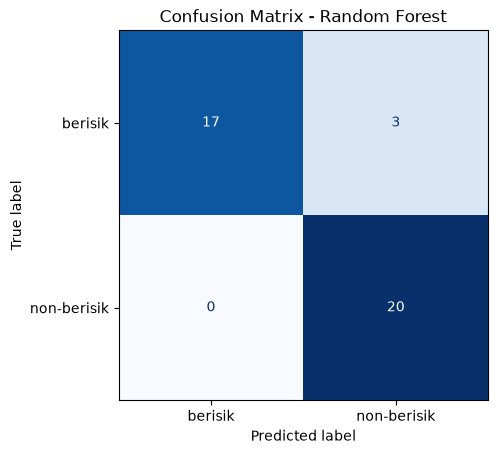

In [21]:
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_rf = GridSearchCV(
    RandomForestClassifier(n_estimators=100, random_state=42),
    param_grid={'max_depth': [None, 5, 10], 'min_samples_leaf': [1, 3, 5]},
    cv=cv, scoring='f1_macro',
)
grid_rf.fit(X_train, y_train)
model_rf = grid_rf.best_estimator_

print(f'Parameter terbaik : {grid_rf.best_params_}')
print(f'F1 CV (5-fold)    : {grid_rf.best_score_:.3f}\n')
print(classification_report(y_test, model_rf.predict(X_test), digits=3))

ConfusionMatrixDisplay.from_estimator(model_rf, X_test, y_test, cmap='Blues', colorbar=False)
plt.title('Confusion Matrix - Random Forest')
plt.show()

Random Forest memperoleh F1 CV 0,855, dengan parameter terbaik `max_depth=10` dan `min_samples_leaf=1`. Pada data uji, akurasinya **0,905**, dan hanya 4 dari 42 file yang salah. Semua kesalahannya searah: 4 rekaman berisik diprediksi non-berisik (recall berisik 0,810), sedangkan seluruh 21 rekaman non-berisik ditebak benar (recall 1,000). Artinya, model ini tidak pernah memberi peringatan palsu pada ruangan tenang di data uji.

### 7.2 Support Vector Machine (SVM)

**Cara kerja.** SVM mencari garis (atau bidang) pemisah dengan **margin terlebar** di antara kedua kelas. Dengan kernel **RBF** (*Radial Basis Function*), data dipetakan ke ruang berdimensi lebih tinggi sehingga batas pemisahnya bisa melengkung:

$$K(\mathbf{x}, \mathbf{x}') = \exp\left(-\gamma\,\lVert\mathbf{x} - \mathbf{x}'\rVert^2\right)$$

- `C` mengatur seberapa keras model menghukum kesalahan pada data latih. Nilai besar membuat batas lebih detail, tetapi berisiko *overfitting*.
- `gamma` mengatur jangkauan pengaruh setiap titik data. Nilai besar membuat batas lebih berkelok-kelok.

SVM bekerja dengan jarak, sehingga fitur berskala besar (centroid dalam ribuan Hz) akan mendominasi fitur berskala kecil (ZCR antara 0 dan 1). Karena itu, fitur distandardisasi lebih dulu dengan `StandardScaler`, yaitu $z = (x - \mu)/\sigma$. Scaler dan model disatukan dalam `Pipeline` agar scaler hanya mempelajari $\mu$ dan $\sigma$ dari data latih di setiap fold.

c:\Users\Administrator\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Administrator\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Administrator\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Administrator\AppData\Local\Programs\Python\Python31

Parameter terbaik : {'svm__C': 10, 'svm__gamma': 'scale'}
F1 CV (5-fold)    : 0.881

              precision    recall  f1-score   support

     berisik      1.000     0.850     0.919        20
 non-berisik      0.870     1.000     0.930        20

    accuracy                          0.925        40
   macro avg      0.935     0.925     0.925        40
weighted avg      0.935     0.925     0.925        40



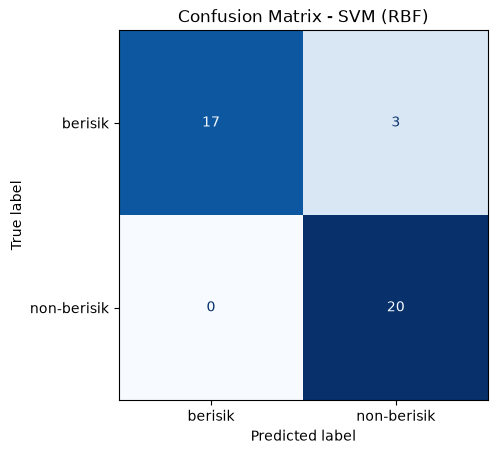

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

grid_svm = GridSearchCV(
    Pipeline([('scaler', StandardScaler()), ('svm', SVC(kernel='rbf', probability=True, random_state=42))]),
    param_grid={'svm__C': [0.1, 1, 10, 100], 'svm__gamma': ['scale', 0.01, 0.1]},
    cv=cv, scoring='f1_macro',
)
grid_svm.fit(X_train, y_train)
model_svm = grid_svm.best_estimator_

print(f'Parameter terbaik : {grid_svm.best_params_}')
print(f'F1 CV (5-fold)    : {grid_svm.best_score_:.3f}\n')
print(classification_report(y_test, model_svm.predict(X_test), digits=3))

ConfusionMatrixDisplay.from_estimator(model_svm, X_test, y_test, cmap='Blues', colorbar=False)
plt.title('Confusion Matrix - SVM (RBF)')
plt.show()

SVM memperoleh F1 CV tertinggi di antara ketiga metode (**0,891**), dengan `C=10` dan `gamma=0.1`. Namun, pada data uji akurasinya turun menjadi **0,833** (7 file salah). Polanya mirip Random Forest: recall non-berisik tinggi (0,952), tetapi recall berisik hanya 0,714. Artinya, SVM lebih sering melewatkan rekaman berisik.

### 7.3 K-Nearest Neighbors (KNN)

**Cara kerja.** KNN tidak membangun model secara eksplisit. Untuk memprediksi satu data baru, KNN mencari $k$ data latih yang **paling dekat** dengannya, lalu mengambil kelas mayoritas dari tetangga-tetangga tersebut. Jarak yang dipakai adalah jarak Euclidean:

$$d(\mathbf{x}, \mathbf{x}') = \sqrt{\sum_{j=1}^{32}(x_j - x'_j)^2}$$

Seperti SVM, KNN sangat bergantung pada skala, sehingga juga memakai `StandardScaler`. Parameter yang di-*tuning* adalah jumlah tetangga (`n_neighbors`) dan cara pembobotan suara tetangga (`weights`): sama rata (`uniform`) atau makin dekat makin berpengaruh (`distance`).

Parameter terbaik : {'knn__n_neighbors': 7, 'knn__weights': 'distance'}
F1 CV (5-fold)    : 0.780

              precision    recall  f1-score   support

     berisik      0.762     0.800     0.780        20
 non-berisik      0.789     0.750     0.769        20

    accuracy                          0.775        40
   macro avg      0.776     0.775     0.775        40
weighted avg      0.776     0.775     0.775        40



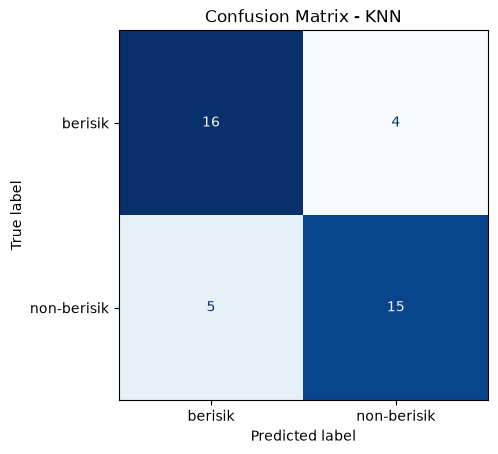

In [23]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

grid_knn = GridSearchCV(
    Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier())]),
    param_grid={'knn__n_neighbors': [3, 5, 7, 9, 11, 15], 'knn__weights': ['uniform', 'distance']},
    cv=cv, scoring='f1_macro',
)
grid_knn.fit(X_train, y_train)
model_knn = grid_knn.best_estimator_

print(f'Parameter terbaik : {grid_knn.best_params_}')
print(f'F1 CV (5-fold)    : {grid_knn.best_score_:.3f}\n')
print(classification_report(y_test, model_knn.predict(X_test), digits=3))

ConfusionMatrixDisplay.from_estimator(model_knn, X_test, y_test, cmap='Blues', colorbar=False)
plt.title('Confusion Matrix - KNN')
plt.show()

KNN memilih `k=3` dengan pembobotan `uniform`, dan F1 CV-nya 0,806, paling rendah di antara ketiga metode. Pada data uji, akurasinya **0,714** (12 file salah), dan kesalahannya terbagi rata di kedua kelas (masing-masing 6 file). Dengan `k` sekecil 3, keputusan KNN sangat bergantung pada beberapa tetangga terdekat yang kebetulan ada di data latih, sehingga kurang stabil saat bertemu rekaman baru.

## 8. Evaluasi

### 8.1 Perbandingan Tiga Metode

Hasil ketiga metode dirangkum dalam satu tabel. **F1 CV** adalah rata-rata 5 fold pada data latih, sedangkan kolom lainnya diukur pada data uji.

In [24]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

models = {'Random Forest': model_rf, 'SVM (RBF)': model_svm, 'KNN': model_knn}
grids = {'Random Forest': grid_rf, 'SVM (RBF)': grid_svm, 'KNN': grid_knn}

ringkasan = []
for nama, model in models.items():
    pred = model.predict(X_test)
    ringkasan.append({
        'Metode': nama,
        'F1 CV (latih)': grids[nama].best_score_,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, average='macro'),
        'Recall': recall_score(y_test, pred, average='macro'),
        'F1 (uji)': f1_score(y_test, pred, average='macro'),
    })

perbandingan = pd.DataFrame(ringkasan).set_index('Metode').round(3)
perbandingan

,F1 CV (latih),Accuracy,Precision,Recall,F1 (uji)
Metode,,,,,
Random Forest,0.786,0.925,0.935,0.925,0.925
SVM (RBF),0.881,0.925,0.935,0.925,0.925
KNN,0.780,0.775,0.776,0.775,0.775


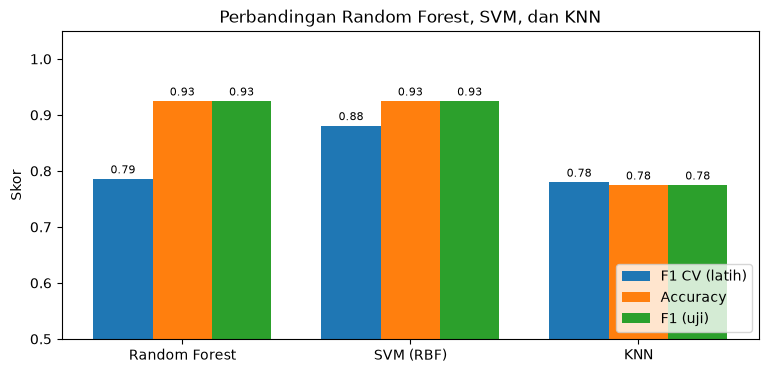

In [25]:
import matplotlib.pyplot as plt
import numpy as np

metrik = ['F1 CV (latih)', 'Accuracy', 'F1 (uji)']
posisi = np.arange(len(perbandingan))
lebar = 0.26

fig, ax = plt.subplots(figsize=(9, 4))
for i, m in enumerate(metrik):
    batang = ax.bar(posisi + (i - 1) * lebar, perbandingan[m], lebar, label=m)
    ax.bar_label(batang, fmt='%.2f', fontsize=8, padding=2)
ax.set_xticks(posisi, perbandingan.index)
ax.set(ylim=(0.5, 1.05), ylabel='Skor', title='Perbandingan Random Forest, SVM, dan KNN')
ax.legend(loc='lower right')
plt.show()

Hasil perbandingan:

- **Random Forest** memiliki skor uji tertinggi: accuracy **0,905** dan F1 **0,904**.
- **SVM** memiliki F1 CV tertinggi (0,891), tetapi skor ujinya turun menjadi 0,831, di posisi kedua.
- **KNN** paling lemah, baik pada CV (0,806) maupun pada data uji (0,714).

Selisih Random Forest dan SVM pada data uji adalah **3 file** (38 lawan 35 benar dari 42). Perbedaan peringkat antara CV dan data uji menunjukkan kedua metode ini cukup bersaing, tetapi pada rekaman yang belum pernah dilihat, Random Forest lebih unggul.

### 8.2 Feature Importance

*Feature importance* menjawab pertanyaan: **fitur mana yang paling diandalkan model?** Dua cara dipakai:

1. **Gini importance (`feature_importances_`)** bawaan Random Forest, seperti pada modul. Nilainya menunjukkan seberapa besar sebuah fitur membantu memurnikan percabangan di seluruh pohon.
2. **Permutation importance** untuk ketiga model. Nilai satu fitur di data uji diacak, lalu diukur seberapa besar akurasi model turun. Makin besar penurunannya, makin penting fitur tersebut. Cara ini dipakai karena SVM dan KNN tidak memiliki `feature_importances_` bawaan.

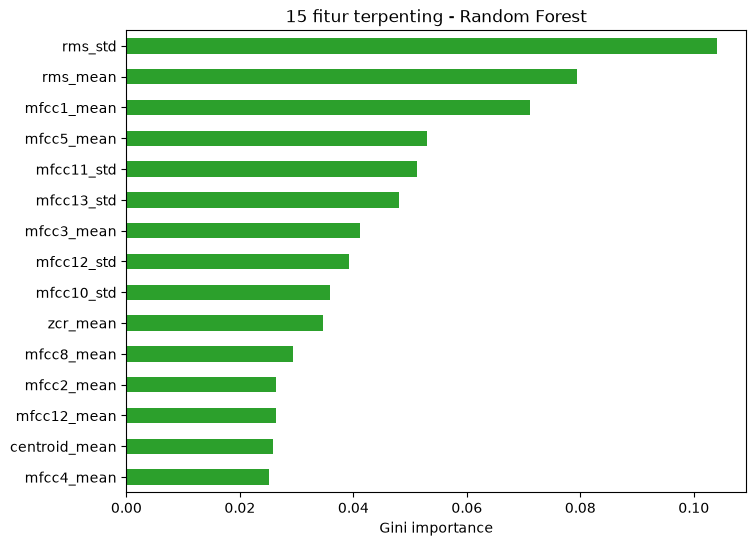

rms_std       0.104
rms_mean      0.079
mfcc1_mean    0.071
mfcc5_mean    0.053
mfcc11_std    0.051
dtype: float64

In [26]:
import matplotlib.pyplot as plt
import pandas as pd

gini = pd.Series(model_rf.feature_importances_, index=FITUR).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
gini.tail(15).plot.barh(ax=ax, color='tab:green')
ax.set(xlabel='Gini importance', title='15 fitur terpenting - Random Forest')
plt.show()

gini.sort_values(ascending=False).head(5).round(3)

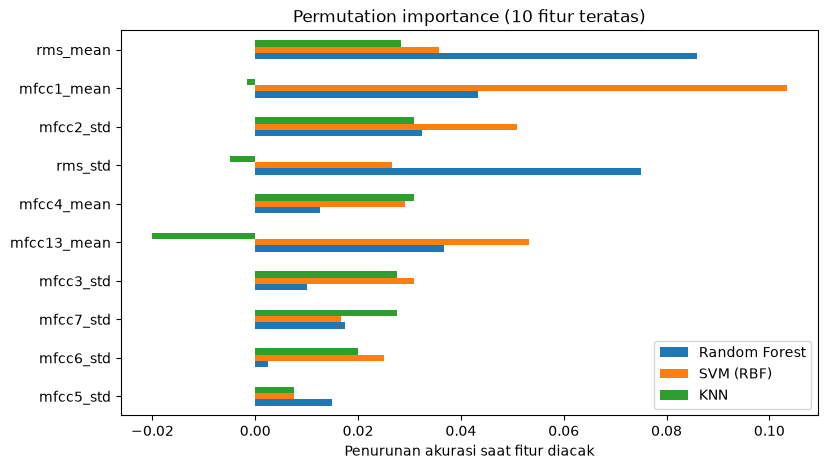

,Random Forest,SVM (RBF),KNN
rms_mean,0.086,0.036,0.028
mfcc1_mean,0.043,0.103,-0.002
mfcc2_std,0.033,0.051,0.031
rms_std,0.075,0.027,-0.005
mfcc4_mean,0.013,0.029,0.031


In [27]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.inspection import permutation_importance

perm = {}
for nama, model in models.items():
    hasil = permutation_importance(model, X_test, y_test, n_repeats=30, random_state=42, scoring='accuracy')
    perm[nama] = pd.Series(hasil.importances_mean, index=FITUR)
perm = pd.DataFrame(perm)

teratas = perm.mean(axis=1).sort_values(ascending=False).head(10).index
fig, ax = plt.subplots(figsize=(9, 5))
perm.loc[teratas[::-1]].plot.barh(ax=ax)
ax.set(xlabel='Penurunan akurasi saat fitur diacak', title='Permutation importance (10 fitur teratas)')
plt.show()

perm.loc[teratas].round(3).head(5)

Kedua cara memberi kesimpulan yang sejalan:

- **Fitur energi paling berpengaruh.** Pada Gini importance Random Forest, tiga fitur teratas adalah `rms_std`, `rms_mean`, dan `mfcc1_mean`, dan ketiganya terkait langsung dengan kenyaringan. Fitur bentuk spektrum seperti `mfcc5_mean` dan `mfcc12_mean` menyusul di bawahnya.
- **`mfcc1_mean` penting bagi ketiga model.** Pada permutation importance, inilah satu-satunya fitur yang menurunkan akurasi ketiga model secara konsisten (sekitar 0,03) saat diacak. Bagi Random Forest, `rms_std` dan `mfcc2_std` paling berpengaruh.
- **Nilai SVM dan KNN kecil, bahkan ada yang negatif.** Data uji hanya 42 file, sehingga satu prediksi yang berubah sudah menggeser akurasi sebesar 0,024. Nilai negatif berarti mengacak fitur tersebut kebetulan tidak menurunkan akurasi. SVM dan KNN memakai jarak di semua 32 fitur sekaligus, sehingga informasinya tersebar di banyak fitur dan tidak ada satu fitur yang sangat menentukan.

### 8.3 Penentuan Metode Terbaik

Metode terbaik ditentukan dari **F1 makro pada data uji**, karena data uji mewakili rekaman baru yang belum pernah dilihat model. Jika skornya sama, dipilih metode dengan F1 CV lebih tinggi karena lebih stabil di berbagai pembagian data.

In [28]:
urut = perbandingan.sort_values(['F1 (uji)', 'F1 CV (latih)'], ascending=False)
METODE_TERBAIK = urut.index[0]
model_terbaik = models[METODE_TERBAIK]

print(f'Metode terbaik : {METODE_TERBAIK}')
print(f'F1 uji         : {urut.loc[METODE_TERBAIK, "F1 (uji)"]:.3f}')
print(f'Accuracy uji   : {urut.loc[METODE_TERBAIK, "Accuracy"]:.3f}')

Metode terbaik : SVM (RBF)
F1 uji         : 0.925
Accuracy uji   : 0.925
